In [25]:
import pandas as pd
import numpy as np

In [26]:
import pandas as pd
import numpy as np

# Load metadata
df_meta = pd.read_excel('data/raw/Supplementary Table S1.xlsx', header=3)
df_meta.rename(columns={
    df_meta.columns[0]: 'Sample id'
}, inplace=True)

def clean_metadata(df):
    # 1. Create Depression Label
    # ICD-10 F32/F33 = Depressive episodes. Healthy = 0.
    df['Depression'] = df['Diagnosis'].apply(lambda x: 1 if 'F3' in str(x) else 0)
    
    # 2. Create Anxiety Label (GAD-7 > 10 is moderate-to-severe anxiety)
    # Use >= 7 to capture the top 40% of anxiety scores in this dataset
    df['Anxiety'] = df['GAD-7'].apply(lambda x: 1 if x >= 7 else 0)
    
    # 3. Clean Metadata Features
    # Convert Sex to binary: Male=0, Female=1
    df['Sex'] = df['Sex'].map({'Male': 0, 'Female': 1})
    
    # Handle BMI: Replace missing (-) with the median
    df['BMI, kg/m2'] = pd.to_numeric(df['BMI, kg/m2'], errors='coerce')
    df['BMI, kg/m2'] = df['BMI, kg/m2'].fillna(df['BMI, kg/m2'].median())
    
    # Keep only target and selected features
    cols_to_keep = ['Sample id', 'Age, y.o.', 'Sex', 'BMI, kg/m2', 'Depression', 'Anxiety']
    return df[cols_to_keep]

df_meta_cleaned = clean_metadata(df_meta)
df_meta_cleaned.to_csv('data/processed/labels_metadata.csv', index=False)
print("Phase 1 Complete: Labels decoded.")

Phase 1 Complete: Labels decoded.


In [27]:
# Load Genus table (S4b)
# Note: In S4b, Genuses are rows and Samples are columns. We need to transpose.
df_genus = pd.read_excel(
    "data/raw/Supplementary Table S4.xlsx",
    sheet_name=1,      # 2nd sheet (0-based index)
    header=1,          # row where HC_1, HC_2... starts
    index_col=0
).T

df_genus.head()

# Merge with Metadata
print(f"Metadata rows: {len(df_meta)}")
print(f"Abundance rows: {len(df_genus)}")
df_final = df_meta_cleaned.merge(df_genus, left_on='Sample id', right_index=True)
print(f"Final merged rows: {len(df_final)}") # This should be ~74

# 1. Rare Taxa Filtering (Keep genera present in >10% of samples)
genus_cols = df_genus.columns
presence_mask = (df_final[genus_cols] > 0).mean() > 0.10
selected_genera = genus_cols[presence_mask]

# 2. CLR Transformation
def clr_transform(data):
    # Add a small pseudocount (1e-6) because log(0) is undefined
    data = data + 1e-6
    log_data = np.log(data)
    # Subtract the geometric mean
    return log_data.sub(log_data.mean(axis=1), axis=0)

df_features = clr_transform(df_final[selected_genera])
# Combine with metadata features (Age, Sex, BMI)
X = pd.concat([df_final[['Age, y.o.', 'Sex', 'BMI, kg/m2']], df_features], axis=1)
Y = df_final[['Depression', 'Anxiety']]

X.to_csv('data/processed/features_X.csv', index=False)
Y.to_csv('data/processed/targets_Y.csv', index=False)


Metadata rows: 74
Abundance rows: 79
Final merged rows: 74


In [ ]:
from boruta import BorutaPy
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import MultiTaskElasticNetCV

# 1. THE ROUGH CUT: Boruta (Targeting the whole Y matrix)
# Since Boruta takes one vector, we create a "Combined" target 
# to ensure we don't miss features relevant to EITHER condition.
y_combined = Y.max(axis=1) # 1 if they have Depression OR Anxiety

rf = RandomForestClassifier(n_jobs=-1, class_weight='balanced', max_depth=5)
boruta_selector = BorutaPy(rf, n_estimators='auto', random_state=42)
boruta_selector.fit(X.values, y_combined.values)

# Features that passed the first "Rough" filter
X_boruta = X.iloc[:, boruta_selector.support_]
print(f"Boruta selected {X_boruta.shape[1]} features.")

# 2. THE PRECISION CUT: Multi-Task Elastic Net
# This is the "Elastic Net" part you were looking for. 
# It finds features that predict both Depression and Anxiety at the same time.
# MultiTaskElasticNetCV automatically finds the best 'alpha' (strength of selection).

mt_en = MultiTaskElasticNetCV(cv=5, random_state=42, selection='random')
mt_en.fit(X_boruta, Y)

# Get the names of features that have a non-zero weight for either task
# If the weight is 0, Elastic Net has 'deleted' that feature.
mten_support = np.sum(np.abs(mt_en.coef_), axis=0) > 0
final_features = X_boruta.columns[mten_support]

X = X[final_features]
print(f"Elastic Net refined this to {len(final_features)} features.")
print("Final Selected Microbiome Markers:", final_features.tolist())


Boruta selected 17 features.
Elastic Net refined this to 13 features.
Final Selected Microbiome Markers: ['Lachnospira', 'Ruthenibacterium', 'Veillonella', 'Gardnerella', 'Pseudobutyrivibrio', 'Kocuria', 'Trueperella', 'Lancefieldella', 'Fructilactobacillus', 'Lachnoanaerobaculum', 'Corynebacterium', 'Raoultella', 'Lawsonella']


In [69]:
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from sklearn.model_selection import cross_val_score

# Use 5-Fold CV to get a 'Real' average score
mksf = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [72]:
# Phase 4: Baseline Multilabel Model (Random Forest)
from sklearn.multioutput import MultiOutputClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, multilabel_confusion_matrix
from skmultilearn.model_selection import iterative_train_test_split

# 1. Split Data (80% Train, 20% Test)
X_train, y_train, X_test, y_test = iterative_train_test_split(X.values, Y.values, test_size=0.2)

# 2. Initialize Multi-Output Random Forest
# We use balanced class weights because mental health datasets are often imbalanced
base_rf = RandomForestClassifier(
    n_estimators=200, 
    class_weight='balanced_subsample', # KEY CHANGE
    max_depth=10, 
    random_state=42
)

multi_rf = MultiOutputClassifier(base_rf)

# 3. Train
depression_auc_scores = []
anxiety_auc_scores = []

all_y_true = []
all_y_pred = []

for train_index, test_index in mksf.split(X, Y):
    X_train_cv, X_test_cv = X.iloc[train_index], X.iloc[test_index]
    y_train_cv, y_test_cv = Y.iloc[train_index], Y.iloc[test_index]
    
    multi_rf.fit(X_train_cv, y_train_cv)
    y_pred = multi_rf.predict(X_test_cv)
    probs = multi_rf.predict_proba(X_test_cv)

# Extract positive class probabilities
    depression_prob = probs[0][:, 1]
    anxiety_prob = probs[1][:, 1]

    # Depression AUC
    if len(np.unique(y_test_cv.iloc[:, 0])) > 1:
        dep_auc = roc_auc_score(y_test_cv.iloc[:, 0], depression_prob)
        depression_auc_scores.append(dep_auc)
        print(f"Depression AUC: {dep_auc:.3f}")

    if len(np.unique(y_test_cv.iloc[:, 1])) > 1:
        anx_auc = roc_auc_score(y_test_cv.iloc[:, 1], anxiety_prob)
        anxiety_auc_scores.append(anx_auc)
        print(f"Anxiety AUC: {anx_auc:.3f}")

    # Store for overall classification report
    all_y_true.append(y_test_cv.values)
    all_y_pred.append(y_pred)

# Combine all folds
all_y_true = np.vstack(all_y_true)
all_y_pred = np.vstack(all_y_pred)

# Final Classification Report
print("\n=== Final Multilabel Classification Report ===\n")

print(classification_report(
    all_y_true,
    all_y_pred,
    target_names=['Depression', 'Anxiety'],
    zero_division=0
))

# Final AUC summary
print("\n=== AUC Summary ===")
print(f"Mean Depression AUC: {np.mean(depression_auc_scores):.3f}")
print(f"Mean Anxiety AUC: {np.mean(anxiety_auc_scores):.3f}")

Depression AUC: 0.786
Anxiety AUC: 0.741
Depression AUC: 0.759
Anxiety AUC: 0.685
Depression AUC: 0.982
Anxiety AUC: 0.750
Depression AUC: 0.673
Anxiety AUC: 0.698
Depression AUC: 0.857
Anxiety AUC: 0.667

=== Final Multilabel Classification Report ===

              precision    recall  f1-score   support

  Depression       0.81      0.72      0.76        36
     Anxiety       0.60      0.31      0.41        29

   micro avg       0.74      0.54      0.62        65
   macro avg       0.71      0.52      0.59        65
weighted avg       0.72      0.54      0.61        65
 samples avg       0.32      0.28      0.29        65


=== AUC Summary ===
Mean Depression AUC: 0.811
Mean Anxiety AUC: 0.708


In [74]:
#Phase 5: Advanced Model (XGBoost with Hyperparameter Tuning)
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    hamming_loss,
    accuracy_score,
    f1_score
)

# 1. Setup Multi-Output XGBoost
xgb = MultiOutputClassifier(XGBClassifier(use_label_encoder=False, eval_metric='logloss'))

# 2. Define Parameters for Tuning
param_grid = {
    'estimator__n_estimators': [50, 100],
    'estimator__max_depth': [3, 5, 7],
    'estimator__learning_rate': [0.01, 0.1]
}

# 3. Grid Search with 5-Fold Cross-Validation
depression_auc_scores = []
anxiety_auc_scores = []

all_y_true = []
all_y_pred = []

for fold, (train_index, test_index) in enumerate(mksf.split(X, Y), 1):
    print(f"\n--- Fold {fold} ---")

    X_train_cv, X_test_cv = X.iloc[train_index], X.iloc[test_index]
    y_train_cv, y_test_cv = Y.iloc[train_index], Y.iloc[test_index]

    # GridSearch inside each fold
    grid_search = GridSearchCV(
        estimator=xgb,
        param_grid=param_grid,
        cv=3,
        scoring='f1_macro',
        n_jobs=-1
    )

    grid_search.fit(X_train_cv, y_train_cv)

    best_model = grid_search.best_estimator_
    print("Best Params:", grid_search.best_params_)

    # Predictions
    y_pred = best_model.predict(X_test_cv)
    y_prob = best_model.predict_proba(X_test_cv)

    depression_prob = y_prob[0][:, 1]
    anxiety_prob = y_prob[1][:, 1]

    # Depression AUC
    if len(np.unique(y_test_cv.iloc[:, 0])) > 1:
        dep_auc = roc_auc_score(y_test_cv.iloc[:, 0], depression_prob)
        depression_auc_scores.append(dep_auc)
        print(f"Depression AUC: {dep_auc:.3f}")
    else:
        print("Depression AUC skipped: only one class present")

    # Anxiety AUC
    if len(np.unique(y_test_cv.iloc[:, 1])) > 1:
        anx_auc = roc_auc_score(y_test_cv.iloc[:, 1], anxiety_prob)
        anxiety_auc_scores.append(anx_auc)
        print(f"Anxiety AUC: {anx_auc:.3f}")
    else:
        print("Anxiety AUC skipped: only one class present")

    all_y_true.append(y_test_cv.values)
    all_y_pred.append(y_pred)

# Combine all folds
all_y_true = np.vstack(all_y_true)
all_y_pred = np.vstack(all_y_pred)

print("\n=== Final XGBoost Multilabel Classification Report ===\n")

print(classification_report(
    all_y_true,
    all_y_pred,
    target_names=['Depression', 'Anxiety'],
    zero_division=0
))

print("\n=== XGBoost AUC Summary ===")

print(f"Mean Depression AUC: {np.mean(depression_auc_scores):.3f}")
print(f"Mean Anxiety AUC: {np.mean(anxiety_auc_scores):.3f}")

print("\n=== Other Multilabel Metrics ===")

print(f"Hamming Loss: {hamming_loss(all_y_true, all_y_pred):.3f}")
print(f"Exact Match Accuracy: {accuracy_score(all_y_true, all_y_pred):.3f}")
print(f"F1 Micro: {f1_score(all_y_true, all_y_pred, average='micro', zero_division=0):.3f}")
print(f"F1 Macro: {f1_score(all_y_true, all_y_pred, average='macro', zero_division=0):.3f}")


--- Fold 1 ---


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:46:24] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:46:24] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 3, 'estimator__n_estimators': 100}
Depression AUC: 0.875
Anxiety AUC: 0.778

--- Fold 2 ---


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:46:26] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:46:26] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 3, 'estimator__n_estimators': 50}
Depression AUC: 0.750
Anxiety AUC: 0.852

--- Fold 3 ---


...

Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 3, 'estimator__n_estimators': 100}
Depression AUC: 0.857
Anxiety AUC: 0.720

--- Fold 4 ---


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:46:31] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:46:31] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 3, 'estimator__n_estimators': 100}
Depression AUC: 0.653
Anxiety AUC: 0.896

--- Fold 5 ---


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:46:34] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:46:34] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 3, 'estimator__n_estimators': 100}
Depression AUC: 0.804
Anxiety AUC: 0.759

=== Final XGBoost Multilabel Classification Report ===

              precision    recall  f1-score   support

  Depression       0.67      0.72      0.69        36
     Anxiety       0.68      0.52      0.59        29

   micro avg       0.67      0.63      0.65        65
   macro avg       0.67      0.62      0.64        65
weighted avg       0.67      0.63      0.65        65
 samples avg       0.36      0.33      0.33        65


=== XGBoost AUC Summary ===
Mean Depression AUC: 0.788
Mean Anxiety AUC: 0.801

=== Other Multilabel Metrics ===
Hamming Loss: 0.297
Exact Match Accuracy: 0.527
F1 Micro: 0.651
F1 Macro: 0.641


In [76]:
#Phase 6: Angelova-style Image Generation (Updated for Selected Features)
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import layers, models, regularizers

# Create folder
os.makedirs('plots/heatmaps', exist_ok=True)

def create_microbiome_images(X_data, folder='plots/heatmaps'):
    # Determine grid size based on the number of features selected in Phase 3
    num_features = X_data.shape[1]
    grid_size = int(np.ceil(np.sqrt(num_features)))
    
    for i in range(len(X_data)):
        # 1. Extract sample and normalize to 0-1 for visualization
        sample_vec = X_data.iloc[i].values
        norm_vec = (sample_vec - sample_vec.min()) / (sample_vec.max() - sample_vec.min() + 1e-6)
        
        # 2. Pad with zeros to make it a perfect square
        padded = np.pad(norm_vec, (0, grid_size**2 - num_features), mode='constant')
        img_grid = padded.reshape(grid_size, grid_size)
        
        # 3. Save as grayscale or viridis heatmap
        plt.imsave(f'{folder}/sample_{i}.png', img_grid, cmap='magma')

create_microbiome_images(X)

import tensorflow as tf
from tensorflow.keras import layers, models
import cv2

def load_images_as_data(image_folder, labels_df):
    images = []
    # Ensure images are loaded in the same order as labels
    for i in range(len(labels_df)):
        img_path = os.path.join(image_folder, f'sample_{i}.png')
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (64, 64)) # Resize for consistency
        images.append(img)
    return np.array(images).reshape(-1, 64, 64, 1) / 255.0

# 1. Prepare Data
X_img = load_images_as_data('plots/heatmaps', Y)
y_img = Y.values # Depression and Anxiety columns

In [77]:
def build_cnn_model():
    model = models.Sequential([
        layers.Conv2D(
            16, (3, 3),
            activation='relu',
            padding='same',
            kernel_regularizer=regularizers.l2(0.001),
            input_shape=(64, 64, 1)
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            32, (3, 3),
            activation='relu',
            padding='same',
            kernel_regularizer=regularizers.l2(0.001)
        ),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),

        layers.Dropout(0.3),
        layers.Dense(2, activation='sigmoid')
    ])

    model.compile(optimizer=Adam(learning_rate=1e-5), loss='binary_crossentropy', metrics=['accuracy'])

    return model

In [ ]:
all_y_true = []
all_y_pred = []

fold_f1_scores = []
fold_hamming_losses = []

histories = []

auc_depression = []
auc_anxiety = []

for fold, (train_idx, val_idx) in enumerate(mksf.split(X_img, y_img), 1):
    print(f"\n--- CNN Fold {fold} ---")

    X_train_fold = X_img[train_idx]
    X_val_fold = X_img[val_idx]

    y_train_fold = y_img[train_idx]
    y_val_fold = y_img[val_idx]

    model = build_cnn_model()

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        ),
        ModelCheckpoint('models/best_cnn_model.keras', monitor='val_loss', save_best_only=True)
    ]

    sample_weights = np.ones(len(y_train_fold))
    sample_weights[y_train_fold[:, 1] == 1] = 2.0

    history = model.fit(
        X_train_fold,
        y_train_fold,
        validation_data=(X_val_fold, y_val_fold),
        epochs=30,
        batch_size=4,
        sample_weight=sample_weights,
        callbacks=callbacks,
        verbose=0
    )
    
    histories.append(history)

    y_prob = model.predict(X_val_fold)
    y_pred = (y_prob >= 0.5).astype(int)
    
    y_val_dep = y_val_fold[:, 0]
    y_val_anx = y_val_fold[:, 1]
    
    y_prob_dep = y_prob[:, 0]
    y_prob_anx = y_prob[:, 1]

    # Compute ROC-AUC separately
    auc_depression.append(roc_auc_score(y_val_dep, y_prob_dep))
    auc_anxiety.append(roc_auc_score(y_val_anx, y_prob_anx))

    all_y_true.append(y_val_fold)
    all_y_pred.append(y_pred)

    fold_f1 = f1_score(y_val_fold, y_pred, average='macro', zero_division=0)
    fold_hl = hamming_loss(y_val_fold, y_pred)

    fold_f1_scores.append(fold_f1)
    fold_hamming_losses.append(fold_hl)

    print(f"Fold {fold} F1 Macro: {fold_f1:.3f}")
    print(f"Fold {fold} Hamming Loss: {fold_hl:.3f}")


--- CNN Fold 1 ---


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
Fold 1 F1 Macro: 0.612
Fold 1 Hamming Loss: 0.500

--- CNN Fold 2 ---


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
Fold 2 F1 Macro: 0.604
Fold 2 Hamming Loss: 0.567

--- CNN Fold 3 ---


...

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
Fold 3 F1 Macro: 0.250
Fold 3 Hamming Loss: 0.600

--- CNN Fold 4 ---


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
Fold 4 F1 Macro: 0.000
Fold 4 Hamming Loss: 0.571

--- CNN Fold 5 ---


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
Fold 5 F1 Macro: 0.318
Fold 5 Hamming Loss: 0.467


In [86]:
print(f"Depression ROC-AUC: {np.mean(auc_depression):.3f} ± {np.std(auc_depression):.3f}")
print(f"Anxiety ROC-AUC: {np.mean(auc_anxiety):.3f} ± {np.std(auc_anxiety):.3f}")

Depression ROC-AUC: 0.407 ± 0.156
Anxiety ROC-AUC: 0.510 ± 0.192


In [ ]:
all_y_true = np.vstack(all_y_true)
all_y_pred = np.vstack(all_y_pred)

print("\n=== Final CNN Cross-Validated Report ===\n")

print(classification_report(
    all_y_true,
    all_y_pred,
    target_names=['Depression', 'Anxiety'],
    zero_division=0
))

print("Mean F1 Macro:", np.mean(fold_f1_scores))
print("Mean Hamming Loss:", np.mean(fold_hamming_losses))


=== Final CNN Cross-Validated Report ===

              precision    recall  f1-score   support

  Depression       0.55      0.33      0.41        36
     Anxiety       0.45      0.17      0.25        29

   micro avg       0.52      0.26      0.35        65
   macro avg       0.50      0.25      0.33        65
weighted avg       0.50      0.26      0.34        65
 samples avg       0.16      0.13      0.14        65

Mean F1 Macro: 0.1913235294117647
Mean Hamming Loss: 0.43285714285714283


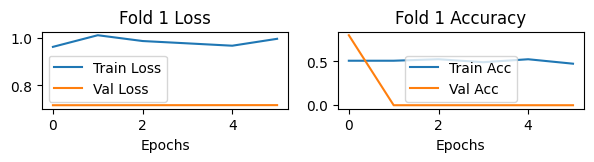

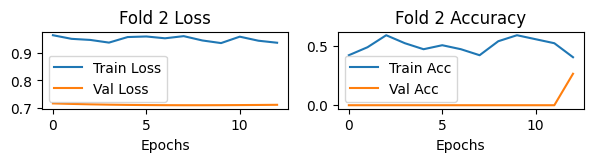

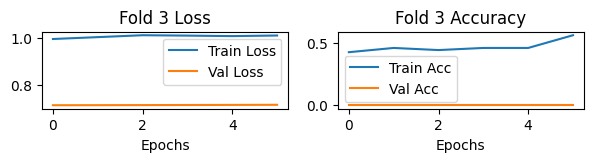

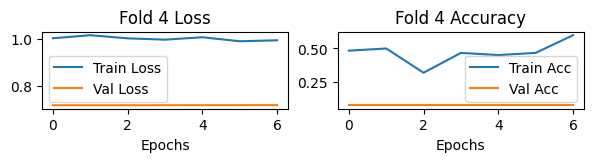

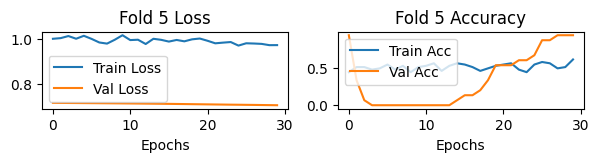

In [83]:
for i, history in enumerate(histories, 1):
    plt.figure(figsize=(7,1))

    # Loss
    plt.subplot(1,2,1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Fold {i} Loss')
    plt.xlabel('Epochs')
    plt.legend()

    # Accuracy
    plt.subplot(1,2,2)
    plt.plot(history.history['accuracy'], label='Train Acc')
    plt.plot(history.history['val_accuracy'], label='Val Acc')
    plt.title(f'Fold {i} Accuracy')
    plt.xlabel('Epochs')
    plt.legend()

    plt.show()